In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [32]:
df = pd.read_csv('WDICSV.csv')
print(df.shape)
df.head()



(398468, 70)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,18.471500,18.822373,19.302882,19.770426,20.120927,20.440680,20.817895,21.161010,21.532841,NaN
1,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.RU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,7.682625,7.953281,8.528101,8.878267,9.050266,9.111884,9.285654,9.403676,9.687390,NaN
2,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.UR.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,39.163151,39.206303,39.406216,39.569413,39.958115,40.025590,40.203585,40.728295,41.118943,NaN
3,Africa Eastern and Southern,AFE,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,38.859598,40.223744,43.035073,44.390861,46.282371,48.127211,48.742043,50.667516,52.598171,NaN
4,Africa Eastern and Southern,AFE,"Access to electricity, rural (% of rural popul...",EG.ELC.ACCS.RU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,24.584906,25.375037,26.941984,28.983183,30.909991,32.709837,33.998179,35.240236,36.080572,NaN


In [33]:
# Desired indicator codes to be used as mentioned in the handout
codes = ['NY.GDP.PCAP.CD', 'NY.GDP.MKTP.KD.ZG', 'FP.CPI.TOTL.ZG', 'SL.UEM.TOTL.ZS',
         'NE.TRD.GNFS.ZS', 'NE.GDI.TOTL.ZS', 'SP.DYN.LE00.IN', 'SP.URB.TOTL.IN.ZS',
         'IT.NET.USER.ZS', 'EG.ELC.ACCS.ZS', 'SE.SEC.ENRR']

n_df = df[df['Indicator Code'].isin(codes)]
n_df = n_df[['Country Name', 'Country Code', 'Indicator Code', '2022']] # choosing the desired columns


req_df = n_df.pivot(index=['Country Name', 'Country Code'], columns='Indicator Code',  values='2022')

req_df = req_df.reset_index()
req_df.columns.name = None   # removes the index column name
print(req_df.shape)

# Changing the column names from codes to socioeconomic indicators
req_df = req_df.rename(columns={ 'NY.GDP.PCAP.CD': 'GDP Per Capita', 'NY.GDP.MKTP.KD.ZG': 'GDP Growth', 'FP.CPI.TOTL.ZG': 'Inflation',
    'SL.UEM.TOTL.ZS': 'Unemployment', 'NE.TRD.GNFS.ZS': 'Trade', 'NE.GDI.TOTL.ZS': 'Capital Formation', 'SP.DYN.LE00.IN': 'Life Expectancy',
    'SP.URB.TOTL.IN.ZS': 'Urban Pop', 'IT.NET.USER.ZS': 'Internet Users', 'EG.ELC.ACCS.ZS': 'Electricity Access', 'SE.SEC.ENRR': 'Secondary Enrollment'})

req_df.iloc[:6]

(266, 13)


,Country Name,Country Code,Electricity Access,Inflation,Internet Users,Capital Formation,Trade,GDP Growth,GDP Per Capita,Secondary Enrollment,Unemployment,Life Expectancy,Urban Pop
0,Afghanistan,AFG,85.300000,13.712102,15.866300,16.700000,72.885470,-6.240172,357.261153,NaN,14.100000,65.617000,25.393925
1,Africa Eastern and Southern,AFE,48.742043,10.883478,26.800000,20.460209,57.117376,3.668029,1675.902524,45.281620,7.869470,64.487152,37.360578
2,Africa Western and Central,AFW,55.585594,7.949251,37.500000,NaN,NaN,4.477108,2143.072094,45.637299,3.596538,57.978995,51.700103
3,Albania,ALB,100.000000,6.725203,82.613675,26.802365,84.698044,4.826801,7756.961887,97.322471,10.785000,78.769000,57.864348
4,Algeria,DZA,100.000000,9.265516,74.781502,35.097954,51.190089,3.600000,4960.303343,104.550270,12.382000,76.129000,74.179586
5,American Samoa,ASM,NaN,NaN,NaN,NaN,124.684271,1.735016,18017.458938,NaN,NaN,72.752000,81.794798


In [34]:
meta_df = pd.read_csv('WDICountry.csv')
meta_df = meta_df[['Country Code', 'Region', 'Income Group']]


merged_df = req_df.merge(meta_df, on='Country Code', how='left')

In [35]:
meta_df.head()

,Country Code,Region,Income Group
0,ABW,Latin America & Caribbean,High income
1,AFE,NaN,NaN
2,AFG,Middle East & North Africa,Low income
3,AFW,NaN,NaN
4,AGO,Sub-Saharan Africa,Lower middle income


Notice there are few countries with **no region specied and no income group specified**

In [36]:
print(merged_df.shape)
final_df = merged_df[merged_df['Income Group'].notna()] # remove the countries which have not been assigned any region or income group
print(final_df.shape)
final_df = final_df.reset_index(drop= True)
final_df


(266, 15)
(217, 15)


,Country Name,Country Code,Electricity Access,Inflation,Internet Users,Capital Formation,Trade,GDP Growth,GDP Per Capita,Secondary Enrollment,Unemployment,Life Expectancy,Urban Pop,Region,Income Group
0,Afghanistan,AFG,85.3,13.712102,15.866300,16.700000,72.885470,-6.240172,357.261153,NaN,14.100,65.617000,25.393925,Middle East & North Africa,Low income
1,Albania,ALB,100.0,6.725203,82.613675,26.802365,84.698044,4.826801,7756.961887,97.322471,10.785,78.769000,57.864348,Europe & Central Asia,Upper middle income
2,Algeria,DZA,100.0,9.265516,74.781502,35.097954,51.190089,3.600000,4960.303343,104.550270,12.382,76.129000,74.179586,Middle East & North Africa,Upper middle income
3,American Samoa,ASM,NaN,NaN,NaN,NaN,124.684271,1.735016,18017.458938,NaN,NaN,72.752000,81.794798,East Asia & Pacific,High income
4,Andorra,AND,100.0,NaN,94.051697,NaN,NaN,9.564612,42414.059011,98.509872,NaN,84.016000,88.754877,Europe & Central Asia,High income
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,Virgin Islands (U.S.),VIR,100.0,NaN,NaN,NaN,205.629281,-1.311232,44320.909186,NaN,12.092,80.319512,95.217151,Latin America & Caribbean,High income
213,West Bank and Gaza,PSE,100.0,3.741224,88.646906,26.523180,82.394928,4.082760,3799.955270,90.136480,24.420,76.662000,86.596142,Middle East & North Africa,Lower middle income
214,"Yemen, Rep.",YEM,76.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.224,67.952000,36.322631,Middle East & North Africa,Low income
215,Zambia,ZMB,47.8,10.993204,15.000000,26.980508,69.297315,5.211224,1447.123101,NaN,5.993,65.279000,44.598851,Sub-Saharan Africa,Lower middle income


Cleanup and Inspection of the Dataset

In [37]:
import seaborn as sns

sns.set_theme(style="whitegrid")
eda_df = final_df.drop(columns=['index'],errors='ignore').copy()

num_cols = ['GDP Per Capita', 'GDP Growth', 'Inflation', 'Unemployment', 'Trade', 'Capital Formation', 'Life Expectancy', 'Urban Pop', 'Internet Users', 'Electricity Access', 'Secondary Enrollment']

print(f"Number of countries: {eda_df.shape[0]}")
print(f"Number of variables: {eda_df.shape[1]}")
print(f"\nWorld Bank Income Group counts: {eda_df['Income Group'].value_counts()}")

missing_summary = pd.DataFrame({
    'Missing Count' : eda_df[num_cols].isna().sum(),
    'Missing %' : (eda_df[num_cols].isna().mean()*100).round(2)
}).sort_values(by='Missing %', ascending = False)

print(missing_summary[missing_summary['Missing Count'] > 0])

#Summary statistics + skewness
summary_stats = eda_df[num_cols].describe().T[['count','mean','50%','std', 'min', '25%', '75%', 'max']]
summary_stats['skewness'] = eda_df[num_cols].skew()
summary_stats = summary_stats.rename(columns={'50%': 'median'})
print("\nSummary Stats for Numerical Indicators")
print(summary_stats.round(2))

print("\nExtreme Observations (Min and Max Countries):")
extremes = []
for col in num_cols:
    valid = eda_df[['Country Name', col]].dropna()
    min_row = valid.loc[valid[col].idxmin()]
    max_row = valid.loc[valid[col].idxmax()]
    extremes.append({
        'Indicator': col,
        'Min Country': min_row['Country Name'],
        'Min Value': round(min_row[col], 2),
        'Max Country': max_row['Country Name'],
        'Max Value': round(max_row[col], 2)
    })
display(pd.DataFrame(extremes))

Number of countries: 217
Number of variables: 15

World Bank Income Group counts: Income Group
High income            86
Upper middle income    59
Lower middle income    47
Low income             25
Name: count, dtype: int64
                      Missing Count  Missing %
Secondary Enrollment             77      35.48
Capital Formation                42      19.35
Inflation                        38      17.51
Internet Users                   35      16.13
Trade                            34      15.67
Unemployment                     31      14.29
GDP Per Capita                    8       3.69
GDP Growth                        8       3.69
Electricity Access                2       0.92

Summary Stats for Numerical Indicators
                      count      mean   median       std     min      25%  \
GDP Per Capita        209.0  21200.87  7655.59  31131.45  301.83  2899.16   
GDP Growth            209.0      4.42     4.25      6.78  -28.76     2.47   
Inflation             179.0     12

,Indicator,Min Country,Min Value,Max Country,Max Value
0,GDP Per Capita,Burundi,301.83,Monaco,226052.06
1,GDP Growth,Ukraine,-28.76,Guyana,63.33
2,Inflation,South Sudan,-6.69,Lebanon,171.21
3,Unemployment,Qatar,0.13,Eswatini,36.47
4,Trade,Sudan,2.70,Luxembourg,412.18
5,Capital Formation,Djibouti,-10.60,Bhutan,55.78
6,Life Expectancy,Central African Republic,18.82,Monaco,85.75
7,Urban Pop,Liechtenstein,14.69,Bahrain,100.00
8,Internet Users,Burundi,7.14,Bahrain,100.00
9,Electricity Access,South Sudan,8.40,Albania,100.00


Analysing Feature Distributions, Skewness, Outliers and Log Transform

GDP Per Capita       | Skewness:   3.06 | Outliers: 16
Inflation            | Skewness:   5.47 | Outliers: 15
Unemployment         | Skewness:   2.00 | Outliers: 12
Life Expectancy      | Skewness:  -1.74 | Outliers: 1
Internet Users       | Skewness:  -0.94 | Outliers: 1
Electricity Access   | Skewness:  -1.87 | Outliers: 37


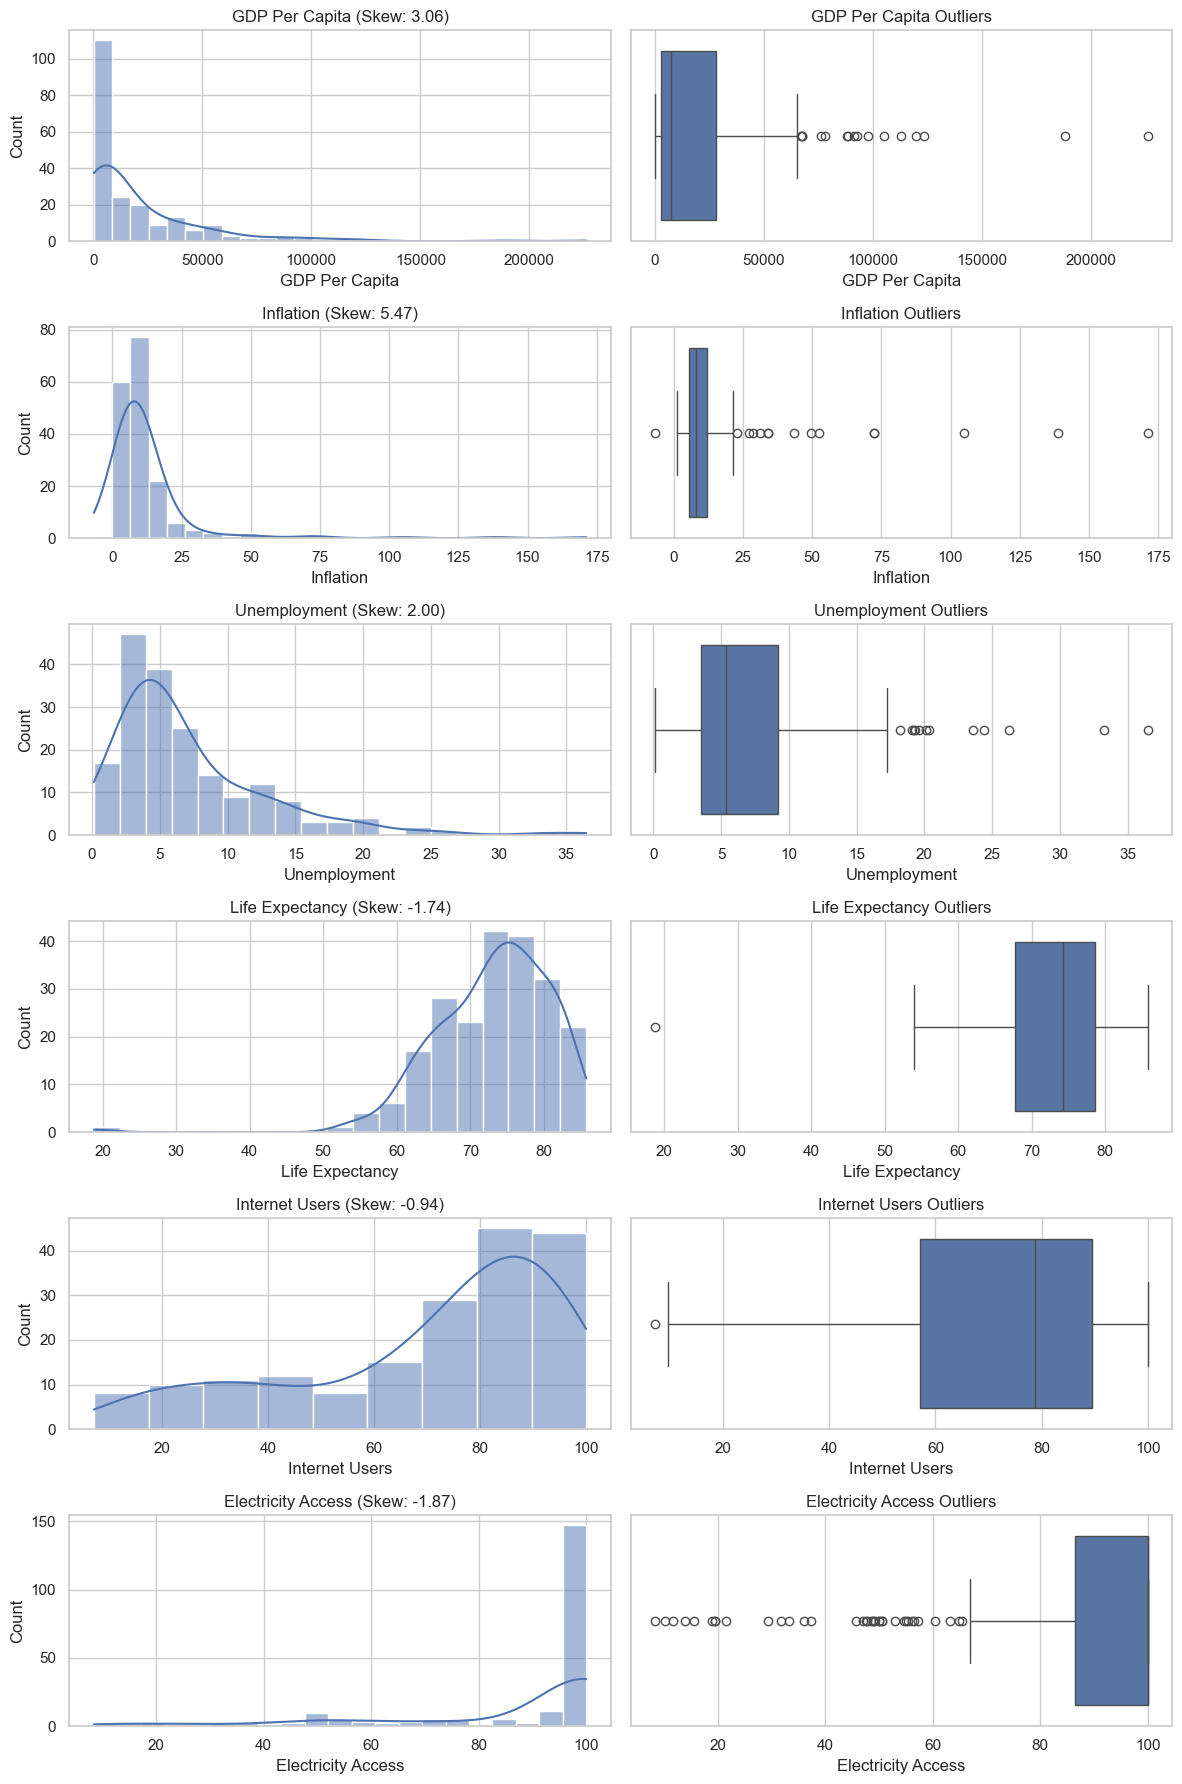

In [38]:
key_indicators = [
    'GDP Per Capita', 'Inflation', 'Unemployment',
    'Life Expectancy', 'Internet Users', 'Electricity Access'
]

for col in key_indicators:
  data = eda_df[col].dropna()
  skew_val = eda_df[col].skew()

  q1 = data.quantile(0.25)
  q3 = data.quantile(0.75)
  iqr = q3 - q1
  outliers = data[(data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)]

  print(f"{col:20} | Skewness: {skew_val:6.2f} | Outliers: {len(outliers)}")

fig, axes = plt.subplots(nrows=len(key_indicators), ncols=2, figsize=(12, 18))

for i, col in enumerate(key_indicators):
    data = eda_df[col].dropna()
    sns.histplot(data, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} (Skew: {data.skew():.2f})")

    sns.boxplot(x=data, ax=axes[i, 1])
    axes[i, 1].set_title(f"{col} Outliers")

plt.tight_layout() # Prevents titles and labels from overlapping
plt.show()



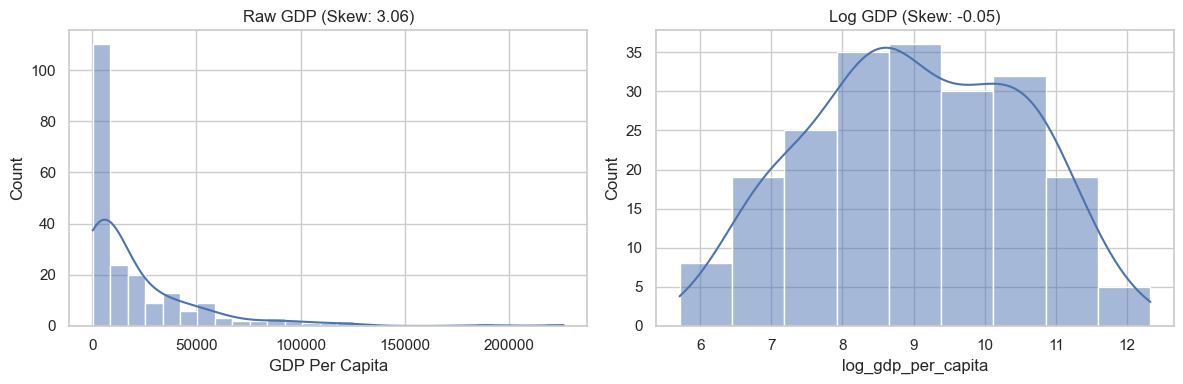

In [39]:
#Applying natural log transformation: x' = ln(x)
eda_df['log_gdp_per_capita'] = np.log(eda_df['GDP Per Capita'])

#Comparing before vs after
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

#Before
sns.histplot(eda_df['GDP Per Capita'].dropna(), kde=True, ax=axes[0])
axes[0].set_title(f"Raw GDP (Skew: {eda_df['GDP Per Capita'].skew():.2f})")

#After
sns.histplot(eda_df['log_gdp_per_capita'].dropna(), kde=True, ax=axes[1])
axes[1].set_title(f"Log GDP (Skew: {eda_df['log_gdp_per_capita'].skew():.2f})")

plt.tight_layout()
plt.show()

Mean and Median by World Bank Income Group:


GDP Per Capita           Internet Users         \
                              mean    median           mean median   
Income Group                                                         
Low income                  754.09    827.33          21.28  18.00   
Lower middle income        2452.11   2325.03          53.46  52.41   
Upper middle income        7342.85   6653.46          75.70  77.66   
High income               46674.85  35653.90          90.26  91.85   

                    Life Expectancy        Electricity Access         
                               mean median               mean median  
Income Group                                                          
Low income                    61.95  63.07              41.28   37.4  
Lower middle income           67.69  67.42              77.56   82.3  
Upper middle income           73.34  74.10              97.34  100.0  
High income                   79.15  80.46              99.86  100.0

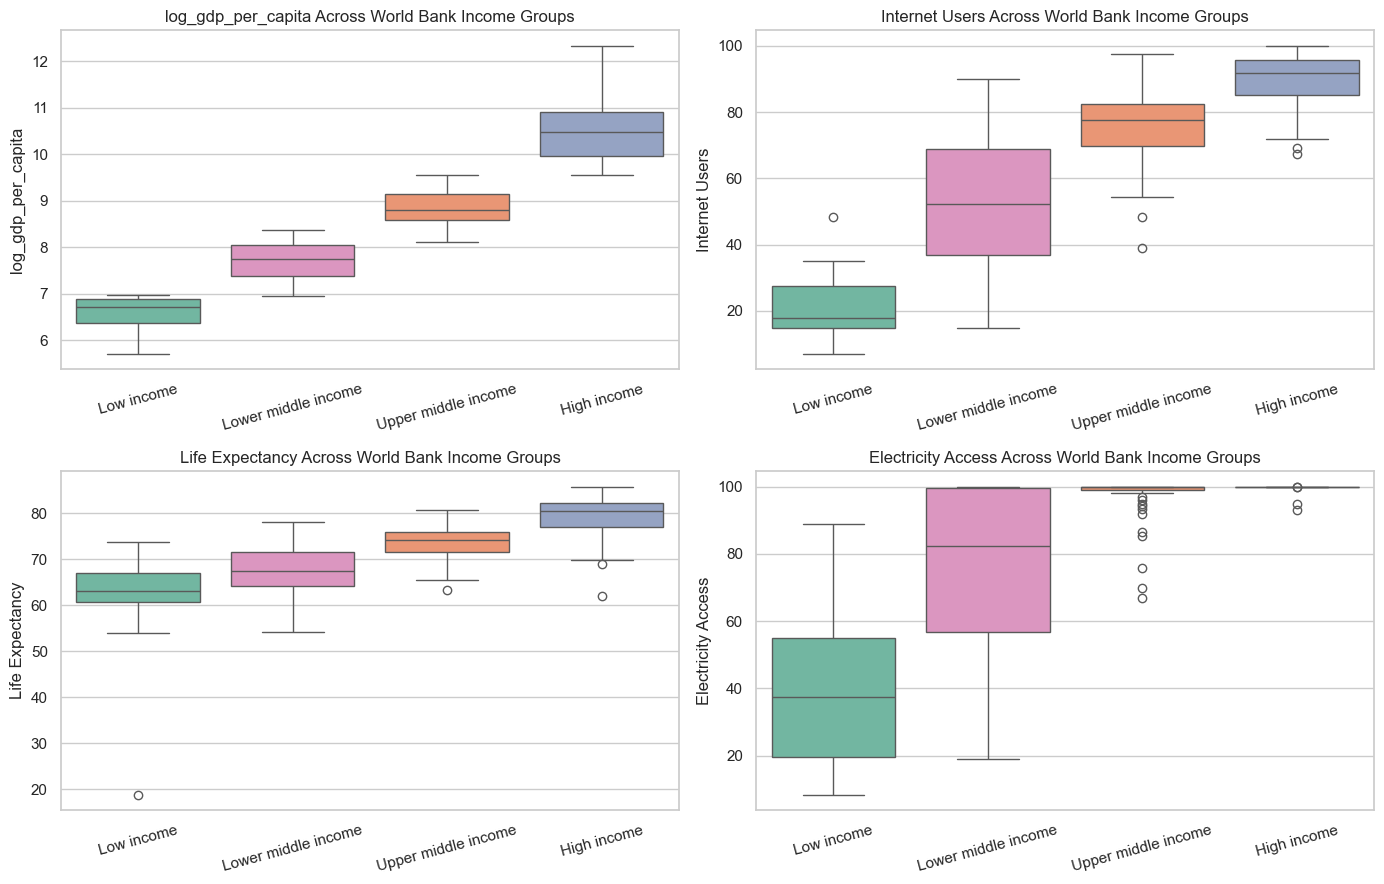

In [40]:
income_order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']
compare_raw = ['GDP Per Capita', 'Internet Users', 'Life Expectancy', 'Electricity Access']
compare_plot = ['log_gdp_per_capita', 'Internet Users', 'Life Expectancy', 'Electricity Access']

print("Mean and Median by World Bank Income Group:")
display(
    eda_df.groupby('Income Group')[compare_raw]
    .agg(['mean', 'median'])
    .reindex(income_order)
    .round(2)
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), compare_plot):
    sns.boxplot(
        data=eda_df, x='Income Group', y=col,
        order=income_order, hue='Income Group',
        palette='Set2', legend=False, ax=ax
    )
    ax.set_title(f"{col} Across World Bank Income Groups")
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [41]:
num_cols = [
    'GDP Per Capita',
    'GDP Growth',
    'Inflation',
    'Unemployment',
    'Trade',
    'Capital Formation',
    'Life Expectancy',
    'Urban Pop',
    'Internet Users',
    'Electricity Access',
    'Secondary Enrollment'
]

# Calculate correlation matrix
corr_matrix = eda_df[num_cols].corr()

display(corr_matrix)

,GDP Per Capita,GDP Growth,Inflation,Unemployment,Trade,Capital Formation,Life Expectancy,Urban Pop,Internet Users,Electricity Access,Secondary Enrollment
GDP Per Capita,1.000000,0.043526,-0.163522,-0.200609,0.413445,-0.029026,0.570266,0.416021,0.516478,0.331719,0.493880
GDP Growth,0.043526,1.000000,-0.118082,0.055970,-0.055196,0.213182,0.040815,-0.070054,0.020032,0.012663,0.039458
Inflation,-0.163522,-0.118082,1.000000,0.058594,-0.160715,-0.277363,-0.056563,-0.029041,-0.071515,-0.051825,-0.110580
Unemployment,-0.200609,0.055970,0.058594,1.000000,0.021294,-0.187762,-0.115047,0.044570,0.003207,-0.011239,0.059608
Trade,0.413445,-0.055196,-0.160715,0.021294,1.000000,-0.054597,0.347630,0.315356,0.413384,0.257147,0.208584
Capital Formation,-0.029026,0.213182,-0.277363,-0.187762,-0.054597,1.000000,0.084886,-0.116670,0.012961,0.072729,-0.040189
Life Expectancy,0.570266,0.040815,-0.056563,-0.115047,0.347630,0.084886,1.000000,0.539116,0.778628,0.733666,0.585306
Urban Pop,0.416021,-0.070054,-0.029041,0.044570,0.315356,-0.116670,0.539116,1.000000,0.696695,0.500083,0.455796
Internet Users,0.516478,0.020032,-0.071515,0.003207,0.413384,0.012961,0.778628,0.696695,1.000000,0.851683,0.690793
Electricity Access,0.331719,0.012663,-0.051825,-0.011239,0.257147,0.072729,0.733666,0.500083,0.851683,1.000000,0.568343


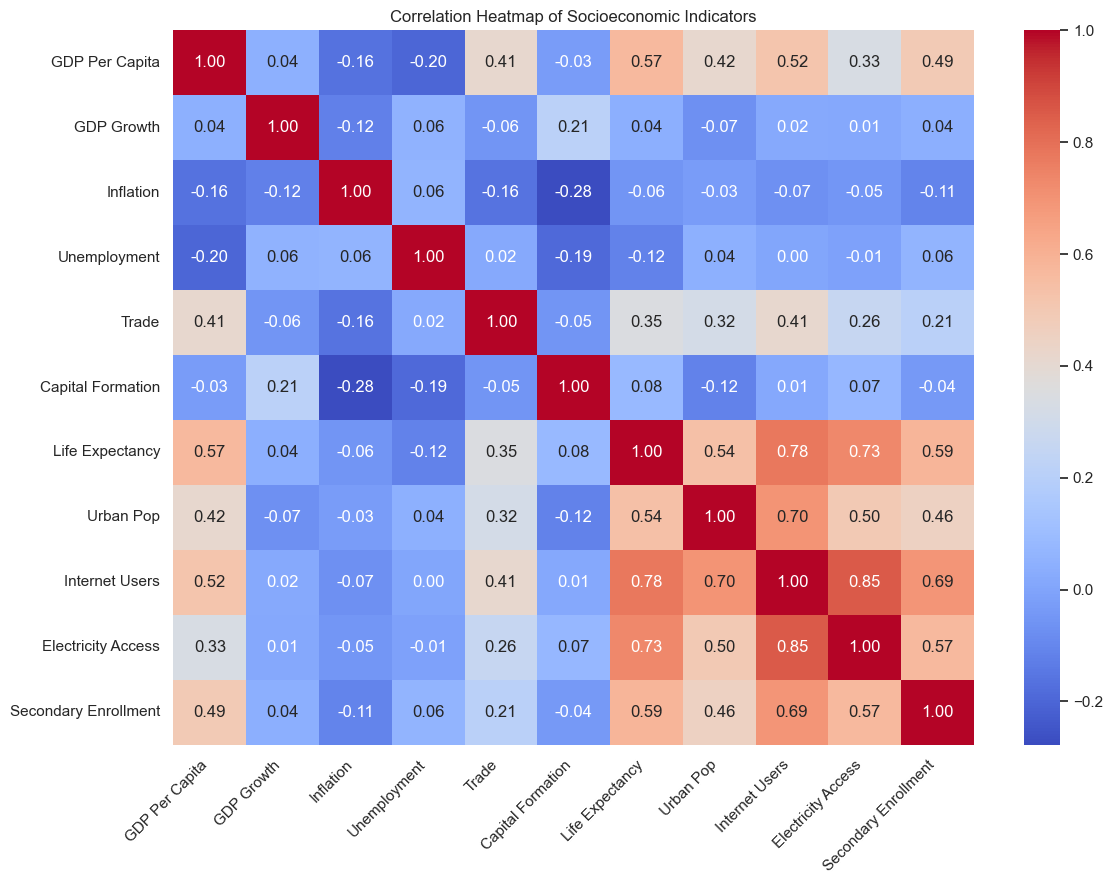

In [42]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Socioeconomic Indicators')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [43]:
threshold = 0.7

print("Potentially Redundant Variables:\n")

for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):

        corr = corr_matrix.iloc[i, j]

        if abs(corr) >= threshold:

            print(num_cols[i], "and", num_cols[j])
            print("Correlation:", round(corr, 3))

            if corr > 0:
                print("Strong positive correlation\n")
            else:
                print("Strong negative correlation\n")

Potentially Redundant Variables:

Life Expectancy and Internet Users
Correlation: 0.779
Strong positive correlation

Life Expectancy and Electricity Access
Correlation: 0.734
Strong positive correlation

Internet Users and Electricity Access
Correlation: 0.852
Strong positive correlation



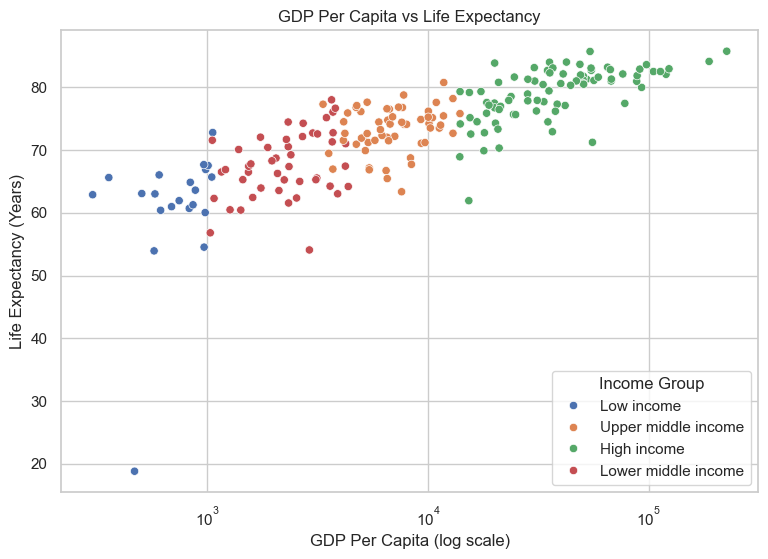

In [44]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eda_df,
    x='GDP Per Capita',
    y='Life Expectancy',
    hue='Income Group'
)

plt.xscale('log')

plt.title('GDP Per Capita vs Life Expectancy')
plt.xlabel('GDP Per Capita (log scale)')
plt.ylabel('Life Expectancy (Years)')

plt.legend(title='Income Group')
plt.show()

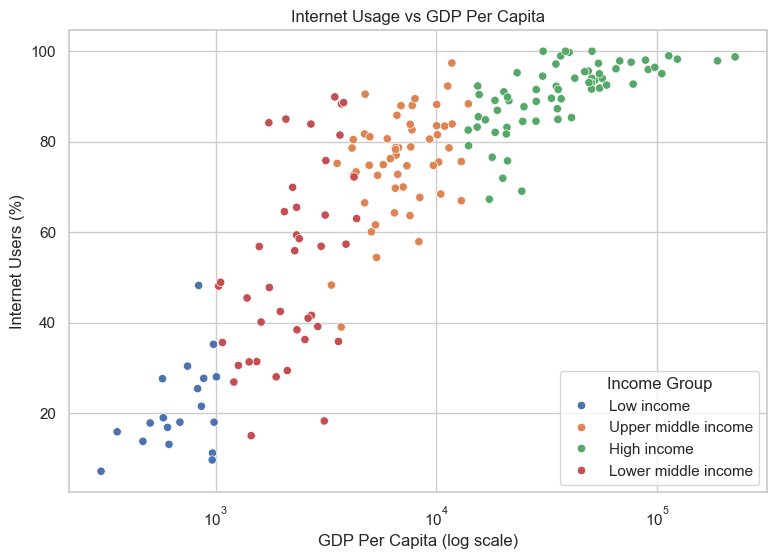

In [45]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eda_df,
    x='GDP Per Capita',
    y='Internet Users',
    hue='Income Group'
)

plt.xscale('log')

plt.title('Internet Usage vs GDP Per Capita')
plt.xlabel('GDP Per Capita (log scale)')
plt.ylabel('Internet Users (%)')

plt.legend(title='Income Group')
plt.show()

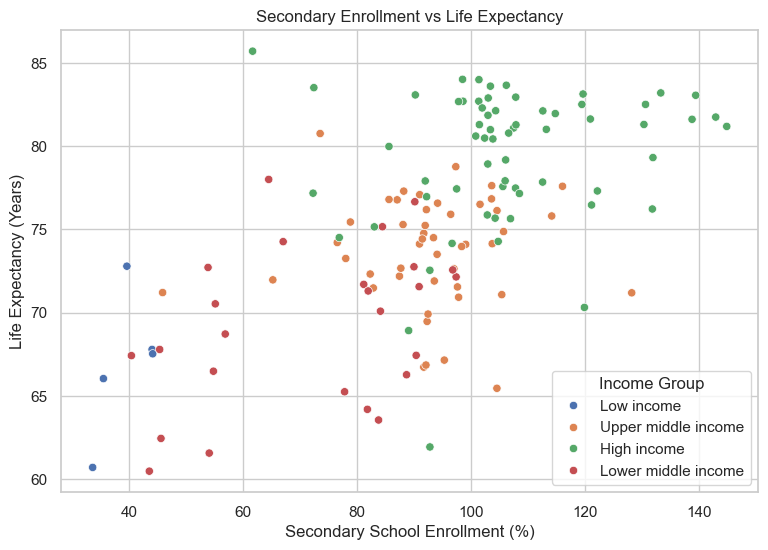

In [46]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eda_df,
    x='Secondary Enrollment',
    y='Life Expectancy',
    hue='Income Group'
)

plt.title('Secondary Enrollment vs Life Expectancy')
plt.xlabel('Secondary School Enrollment (%)')
plt.ylabel('Life Expectancy (Years)')

plt.legend(title='Income Group')
plt.show()

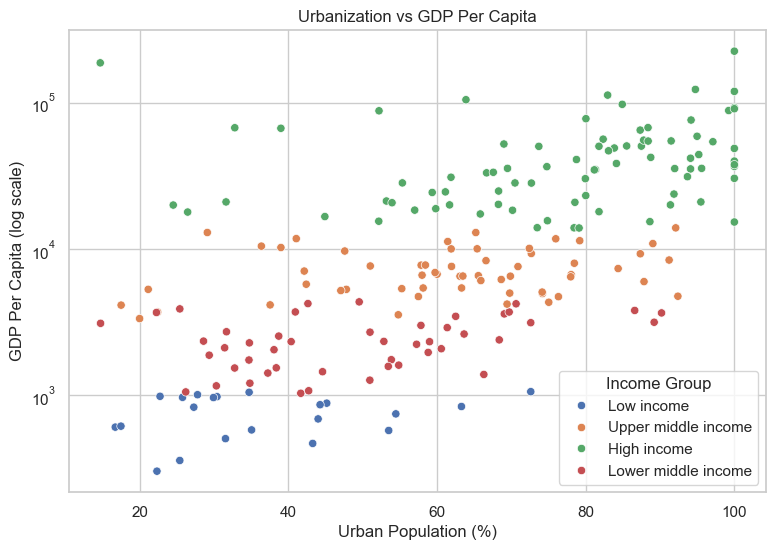

In [47]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eda_df,
    x='Urban Pop',
    y='GDP Per Capita',
    hue='Income Group'
)

plt.yscale('log')

plt.title('Urbanization vs GDP Per Capita')
plt.xlabel('Urban Population (%)')
plt.ylabel('GDP Per Capita (log scale)')

plt.legend(title='Income Group')
plt.show()

Countries retained: 198 / 217 (dropped 19 sparse countries)
Total NaN entries after imputation: 0
X_scaled matrix shape: (198, 11)
Feature means (approx 0): [-0. -0.  0. -0.  0.  0. -0.  0.  0.  0.  0.]
Feature stds  (approx 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


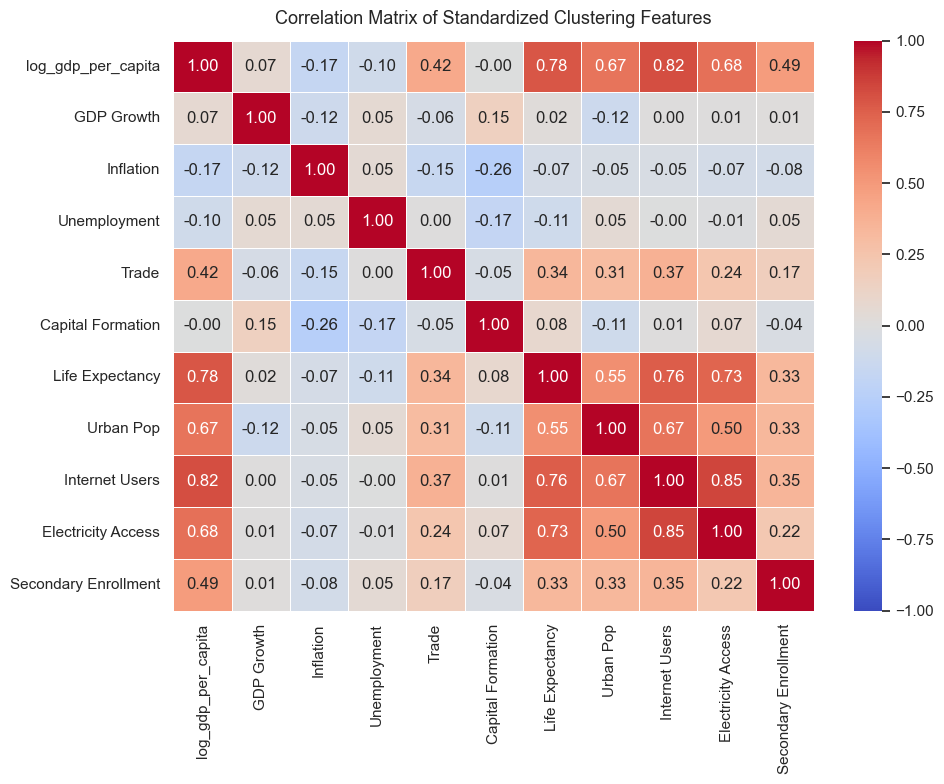

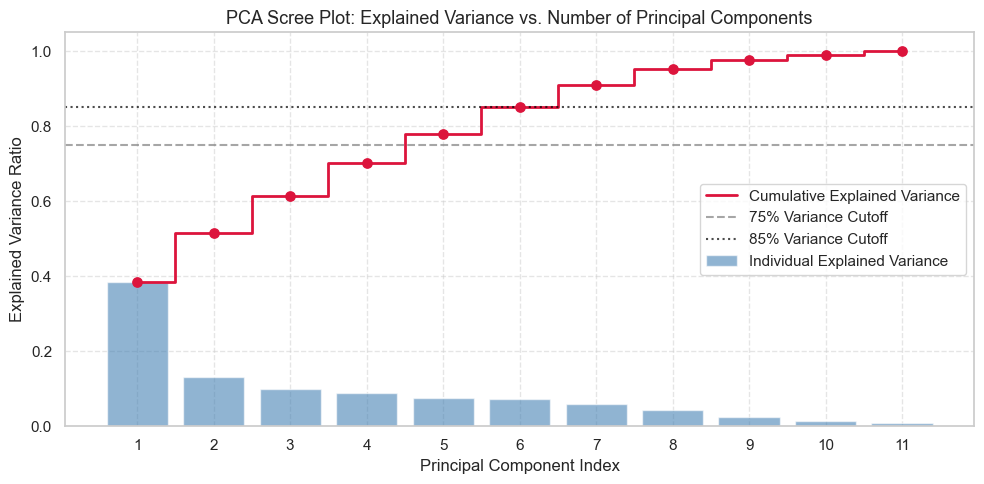


PCA Variance Explained Table:


,Principal Component,Eigenvalue (Variance),Explained Variance Ratio (%),Cumulative Variance (%)
0,PC1,4.244,38.39,38.39
1,PC2,1.441,13.04,51.42
2,PC3,1.091,9.87,61.29
3,PC4,0.989,8.95,70.24
4,PC5,0.845,7.64,77.89
5,PC6,0.788,7.13,85.01
6,PC7,0.647,5.85,90.87
7,PC8,0.476,4.31,95.18
8,PC9,0.273,2.47,97.65
9,PC10,0.159,1.44,99.09



Component Loadings for Top 3 Principal Components:


,PC1_Loading,PC2_Loading,PC3_Loading
log_gdp_per_capita,0.450,0.042,0.027
GDP Growth,-0.002,0.391,0.571
Inflation,-0.072,-0.517,-0.211
Unemployment,-0.021,-0.331,0.722
Trade,0.237,-0.033,0.040
Capital Formation,0.008,0.649,-0.107
Life Expectancy,0.422,0.061,-0.106
Urban Pop,0.368,-0.190,-0.001
Internet Users,0.450,-0.038,-0.023
Electricity Access,0.403,0.039,-0.075


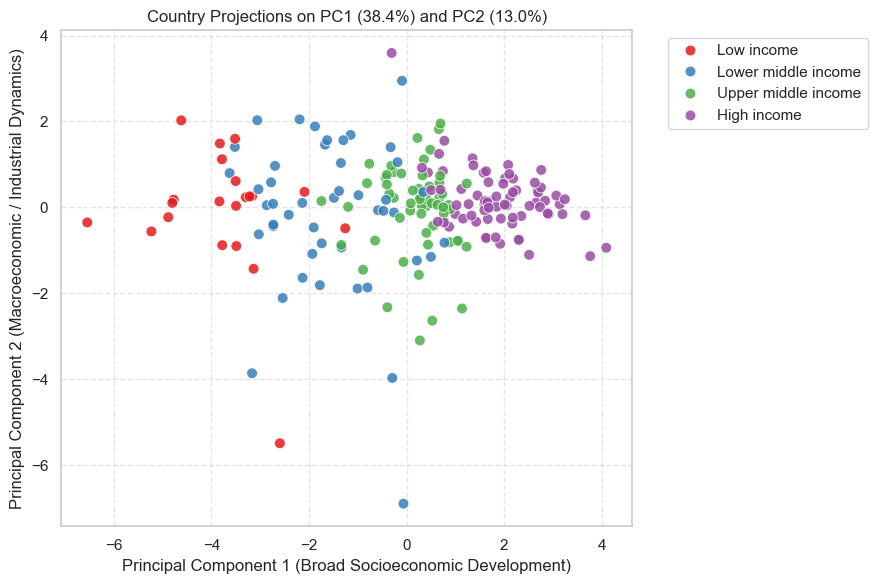

In [48]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer


#Using Log GDP Per Capita in the feature matrix to eliminate extreme right skew
income_order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']
clustering_features = [
    'log_gdp_per_capita', 'GDP Growth', 'Inflation', 'Unemployment',
    'Trade', 'Capital Formation', 'Life Expectancy', 'Urban Pop',
    'Internet Users', 'Electricity Access', 'Secondary Enrollment'
]

# Drop countries missing > 4 out of 11 indicators so heavy imputation doesn't distort clusters
missing_per_country = eda_df[clustering_features].isna().sum(axis=1)
model_df = eda_df[missing_per_country <= 4].reset_index(drop=True)
print(f"Countries retained: {len(model_df)} / {len(eda_df)} (dropped {len(eda_df) - len(model_df)} sparse countries)")

#Median Imputation
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(model_df[clustering_features])

#Verifying that there are 0 missing values
print(f"Total NaN entries after imputation: {np.isnan(X_imputed).sum()}")

#Standardization to zero mean and unit variance (mu = 0, sigma = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print(f"X_scaled matrix shape: {X_scaled.shape}")
print(f"Feature means (approx 0): {X_scaled.mean(axis=0).round(2)}")
print(f"Feature stds  (approx 1): {X_scaled.std(axis=0).round(2)}")

#correlation analysis on standardized features
corr_matrix = pd.DataFrame(X_scaled, columns=clustering_features).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title('Correlation Matrix of Standardized Clustering Features', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

#PCA
#Fitting full 11 components to inspect total variance spectrum
pca_full = PCA(n_components=len(clustering_features))
pca_full.fit(X_scaled)

exp_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var)
components = np.arange(1, len(clustering_features) + 1)

# Scree and Cumulative Explained Variance Plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(components, exp_var, alpha=0.6, color='steelblue', label='Individual Explained Variance')
ax.step(components, cum_var, where='mid', color='crimson', linewidth=2, label='Cumulative Explained Variance')
ax.scatter(components, cum_var, color='crimson', s=45, zorder=5)
ax.axhline(y=0.75, color='gray', linestyle='--', alpha=0.7, label='75% Variance Cutoff')
ax.axhline(y=0.85, color='black', linestyle=':', alpha=0.7, label='85% Variance Cutoff')

ax.set_title('PCA Scree Plot: Explained Variance vs. Number of Principal Components', fontsize=13)
ax.set_xlabel('Principal Component Index')
ax.set_ylabel('Explained Variance Ratio')
ax.set_xticks(components)
ax.set_ylim(0, 1.05)
ax.legend(loc='center right')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#Printing variance explained table
var_table = pd.DataFrame({
    'Principal Component': [f'PC{i}' for i in components],
    'Eigenvalue (Variance)': pca_full.explained_variance_.round(3),
    'Explained Variance Ratio (%)': (exp_var * 100).round(2),
    'Cumulative Variance (%)': (cum_var * 100).round(2)
})
print("\nPCA Variance Explained Table:")
display(var_table)

#Interpreting principal component loadings
loadings_df = pd.DataFrame(
    pca_full.components_[:3].T,
    index=clustering_features,
    columns=['PC1_Loading', 'PC2_Loading', 'PC3_Loading']
)
print("\nComponent Loadings for Top 3 Principal Components:")
display(loadings_df.round(3))

#Using 2d features over 3d features as
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

#Visualization of countries projected onto PC1 vs PC2
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_pca_2d[:, 0],
    y=X_pca_2d[:, 1],
    hue=model_df['Income Group'],
    hue_order=income_order,
    palette='Set1',
    s=60,
    alpha=0.85
)
plt.title(f"Country Projections on PC1 ({exp_var[0]*100:.1f}%) and PC2 ({exp_var[1]*100:.1f}%)")
plt.xlabel("Principal Component 1 (Broad Socioeconomic Development)")
plt.ylabel("Principal Component 2 (Macroeconomic / Industrial Dynamics)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


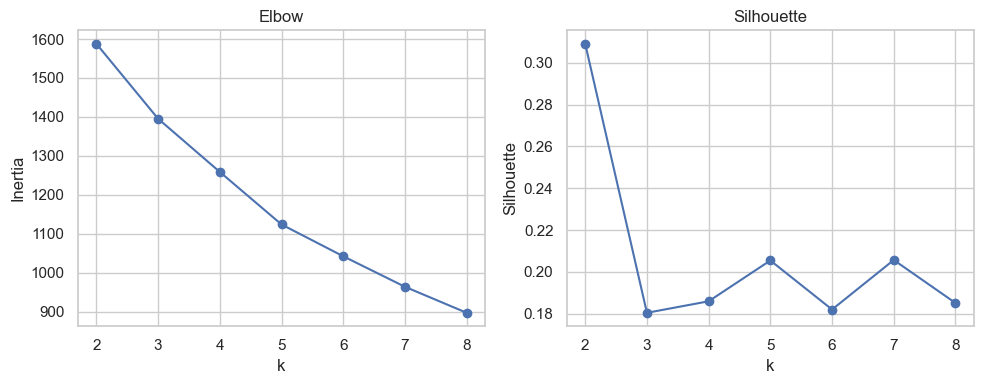

Silhouette k: 2 | Elbow k: 3


In [49]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# Evaluate optimal K using Silhouette Analysis and Inertia
inertia = []
silhouette_scores = []
K_range = range(2, 9)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

K_silhouette = 2 + np.argmax(silhouette_scores)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1);
plt.plot(K_range, inertia, 'o-');
plt.xlabel('k');
plt.ylabel('Inertia');
plt.title('Elbow')

plt.subplot(1, 2, 2); plt.plot(K_range, silhouette_scores, 'o-');
plt.xlabel('k');
plt.ylabel('Silhouette');
plt.title('Silhouette')
plt.tight_layout();
plt.show()

K_elbow = 3 + np.argmax(np.diff(inertia, 2))   # k where the curve bends most sharply
print("Silhouette k:",K_silhouette , "| Elbow k:", K_elbow)





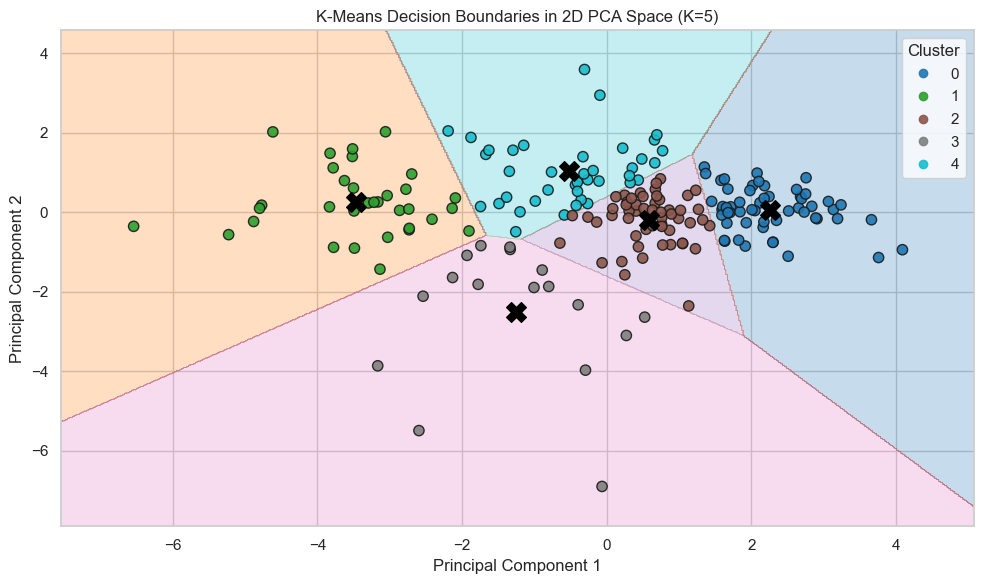

In [53]:
# Fitting K-means to preprocessed data
K_opt = 5  # K = 3 seems optimal value as inertia drop from prev k is also high enough and silhouette score is not much lower than the highest score (k = 2)
kmeans_2d = KMeans(n_clusters= K_opt, init="k-means++", n_init=10, random_state=42)
labels_2d = kmeans_2d.fit_predict(X_pca_2d)
centroids_2d = kmeans_2d.cluster_centers_

# Creating a mesh grid for decision boundaries
x_min, x_max = X_pca_2d[:, 0].min() - 1, X_pca_2d[:, 0].max() + 1
y_min, y_max = X_pca_2d[:, 1].min() - 1, X_pca_2d[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02)
)

# Predict cluster for each point on the grid
Z = kmeans_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 6))

# Decision boundaries (matching colormap)
plt.contourf(xx, yy, Z, alpha=0.25, cmap="tab10")

# Clusters
scatter = plt.scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=labels_2d, cmap="tab10", edgecolors="k", s=55, alpha=0.9
)

# Centroids
plt.scatter(
    centroids_2d[:, 0], centroids_2d[:, 1],
    c="black", marker="X", s=200, label="Centroids"
)

plt.title(f"K-Means Decision Boundaries in 2D PCA Space (K={K_opt})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(*scatter.legend_elements(), title="Cluster", loc="upper right")
plt.tight_layout()
plt.show()

K-Means Silhouette on X_scaled (K=5): 0.2055


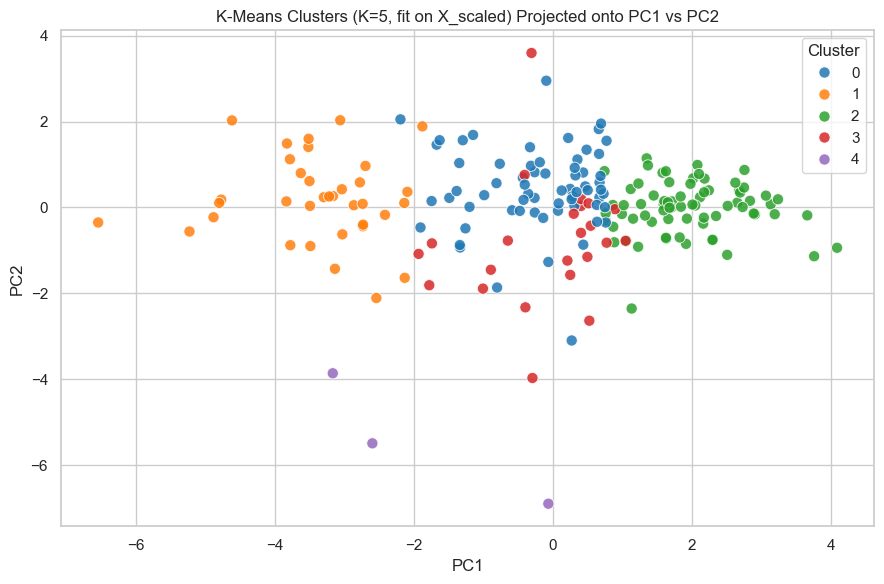


Cluster Profiles (Mean Values)


,GDP Per Capita,GDP Growth,Inflation,Unemployment,Life Expectancy,Internet Users,Electricity Access,Secondary Enrollment
KMeans_Cluster,,,,,,,,
0,6696.51,3.76,11.35,5.61,72.59,72.97,97.16,83.77
1,1255.47,4.08,11.98,5.70,61.61,26.93,45.71,49.39
2,42167.94,3.94,10.24,5.45,79.40,90.54,99.95,108.62
3,6526.10,8.00,7.61,17.61,70.97,71.54,87.61,97.14
4,2412.33,1.52,138.24,9.57,68.69,58.86,71.10,64.50



K-Means Cluster vs World Bank Income Group (%) 


Income Group,Low income,Lower middle income,Upper middle income,High income
KMeans_Cluster,,,,
0,1.5,30.8,55.4,12.3
1,54.3,45.7,0.0,0.0
2,0.0,0.0,11.1,88.9
3,0.0,34.8,60.9,4.3
4,33.3,66.7,0.0,0.0


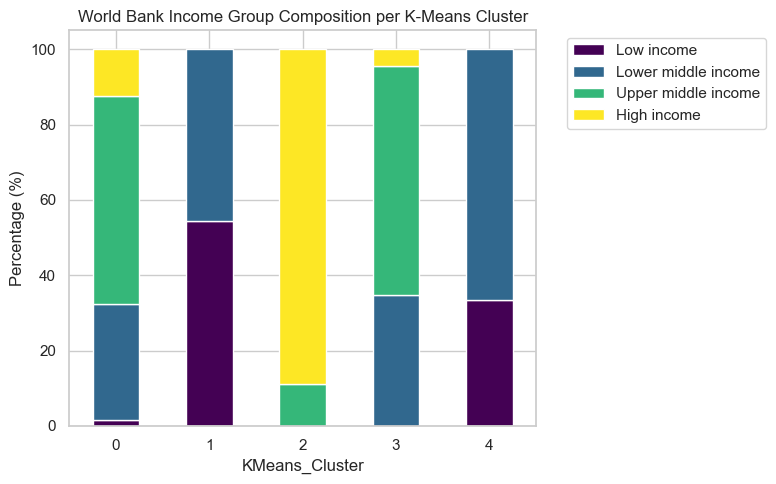


K-Means Cluster vs Region (Counts)


Region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,Middle East & North Africa,North America,South Asia,Sub-Saharan Africa
KMeans_Cluster,,,,,,,
0,17,15,17,6,0,6,4
1,2,0,1,1,0,0,31
2,13,35,13,8,3,0,0
3,0,3,5,6,0,0,9
4,0,0,0,1,0,0,2



Top 10 Most Unusual Countries (Farthest from Cluster Centroid)


,Country Name,Income Group,Region,KMeans_Cluster,Dist_to_Centroid
76,Guyana,High income,Latin America & Caribbean,3,8.59
34,Central African Republic,Low income,Sub-Saharan Africa,1,5.67
185,Ukraine,Upper middle income,Europe & Central Asia,0,5.33
49,Djibouti,Lower middle income,Middle East & North Africa,3,5.29
106,Luxembourg,High income,Europe & Central Asia,2,4.97
151,San Marino,High income,Europe & Central Asia,2,4.86
79,"Hong Kong SAR, China",High income,East Asia & Pacific,2,4.65
177,Timor-Leste,Lower middle income,East Asia & Pacific,0,4.49
57,Eswatini,Lower middle income,Sub-Saharan Africa,3,4.19
182,Turkiye,Upper middle income,Europe & Central Asia,2,4.11


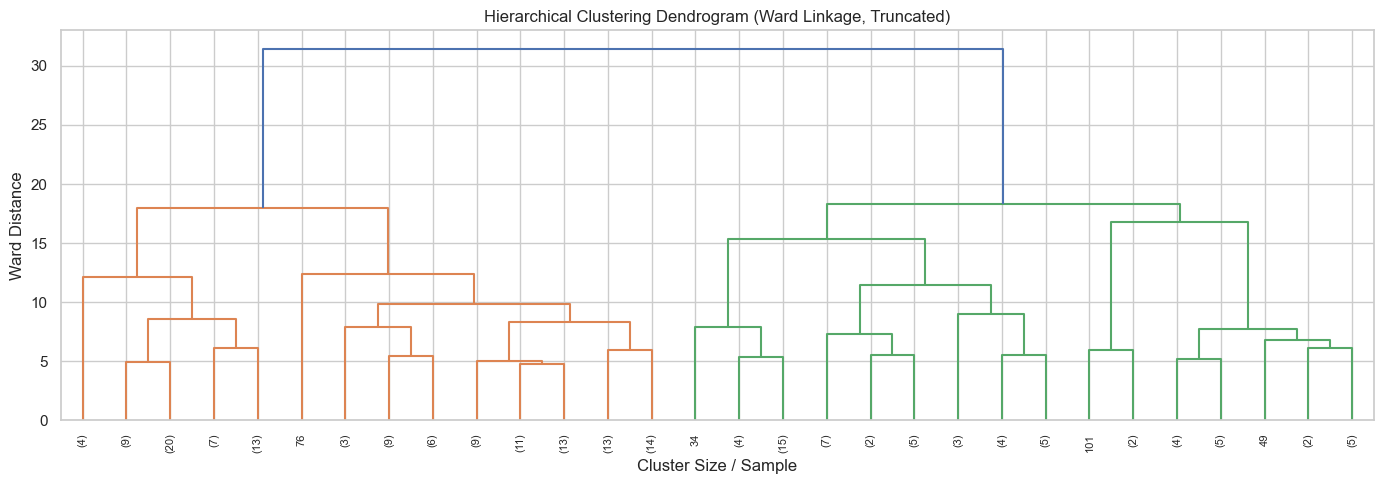

Hierarchical Silhouette on X_scaled (K=5): 0.1606

K-Means vs Hierarchical Clustering Agreement


HC_Cluster,0,1,2,3,4
KMeans_Cluster,,,,,
0,15,50,0,0,0
1,30,1,4,0,0
2,1,18,0,53,0
3,0,10,13,0,0
4,0,0,0,0,3


In [55]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Fit K-Means on full standardized features (X_scaled)
K_opt = 5  # Compare K=4 and K=5 based on Elbow/Silhouette on X_scaled
kmeans_full = KMeans(n_clusters=K_opt, init='k-means++', n_init=10, random_state=42)
model_df['KMeans_Cluster'] = kmeans_full.fit_predict(X_scaled)
print(f"K-Means Silhouette on X_scaled (K={K_opt}): {silhouette_score(X_scaled, model_df['KMeans_Cluster']):.4f}")

# Visualize K-Means (fit on X_scaled) in 2D PCA space
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=X_pca_2d[:, 0], y=X_pca_2d[:, 1],
    hue=model_df['KMeans_Cluster'], palette='tab10', s=65, alpha=0.85
)
plt.title(f"K-Means Clusters (K={K_opt}, fit on X_scaled) Projected onto PC1 vs PC2")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

# 2. Cluster Profiles (Mean of key indicators per cluster)
print("\nCluster Profiles (Mean Values)")
profile_cols = ['GDP Per Capita', 'GDP Growth', 'Inflation', 'Unemployment', 'Life Expectancy', 'Internet Users', 'Electricity Access', 'Secondary Enrollment']
display(model_df.groupby('KMeans_Cluster')[profile_cols].mean().round(2))

# 3. Compare Clusters with World Bank Income Group & Region (Evaluation Only)
print("\nK-Means Cluster vs World Bank Income Group (%) ")
ct_income = pd.crosstab(model_df['KMeans_Cluster'], model_df['Income Group'], normalize='index') * 100
display(ct_income[income_order].round(1))

ct_income[income_order].plot(kind='bar', stacked=True, figsize=(8, 5), colormap='viridis')
plt.title("World Bank Income Group Composition per K-Means Cluster")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("\nK-Means Cluster vs Region (Counts)")
display(pd.crosstab(model_df['KMeans_Cluster'], model_df['Region']))

# 4. Identify Unusual / Outlier Countries (Farthest from assigned centroid)
distances = np.linalg.norm(X_scaled - kmeans_full.cluster_centers_[model_df['KMeans_Cluster']], axis=1)
model_df['Dist_to_Centroid'] = distances
print("\nTop 10 Most Unusual Countries (Farthest from Cluster Centroid)")
display(model_df.nlargest(10, 'Dist_to_Centroid')[['Country Name', 'Income Group', 'Region', 'KMeans_Cluster', 'Dist_to_Centroid']].round(2))

# 5. Hierarchical Clustering (Ward Linkage) & Comparison with K-Means
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=8)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage, Truncated)")
plt.xlabel("Cluster Size / Sample")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

hc = AgglomerativeClustering(n_clusters=K_opt, linkage='ward')
model_df['HC_Cluster'] = hc.fit_predict(X_scaled)
print(f"Hierarchical Silhouette on X_scaled (K={K_opt}): {silhouette_score(X_scaled, model_df['HC_Cluster']):.4f}")

print("\nK-Means vs Hierarchical Clustering Agreement")
display(pd.crosstab(model_df['KMeans_Cluster'], model_df['HC_Cluster']))